# 5. Modelo híbrido: SVR + random forest

Los capítulos 3 y 4 mostraron dos modelos con fortalezas distintas. El **SVR lineal** acierta bien el nivel normal de la temporada, pero se queda corto en las semanas lluviosas. El **random forest** capta umbrales y combinaciones de pistas, pero es más ruidoso. Este capítulo evalúa si **combinarlos** da un pronóstico mejor que cada uno por separado.

**Cómo se combina (apilamiento o *stacking*).** Un "juez" pondera los dos pronósticos:

$$\hat y_{\text{híbrido}} = \max\big(0,\; b + w_1\,\hat y_{\text{SVR}} + w_2\,\hat y_{\text{RF}}\big),\qquad w_1, w_2 \ge 0$$

Los pesos se aprenden por mínimos cuadrados no negativos, como propone Breiman (1996) para el apilamiento en regresión (Wolpert, 1992), **solo con pronósticos fuera de muestra de la validación cruzada temporal** (simulacros 1981–2020). Nunca se usa la prueba 2021–2025. Para comparar en validación con honestidad, en cada simulacro el juez solo conoce los simulacros anteriores.

**Candidatos.** SVR lineal, random forest, el híbrido y un **gradient boosting por histogramas**, que es el mismo algoritmo que XGBoost (modo `hist`) y LightGBM. Sus hiperparámetros, como los del random forest, se eligen por validación cruzada. **Referencias tradicionales:** climatología, promedio (Dummy) y persistencia semanal.

**Criterio de elección, fijado antes de ver los resultados:**

1. Se elige el modelo con **menor error cuadrático medio (MSE) en validación**, en promedio sobre los horizontes de 1 a 4 semanas.
2. Si la diferencia con el segundo es menor de 1 %, desempata la **detección de aguaceros en validación** (índice CSI).
3. La prueba 2021–2025 se usa **una sola vez y solo para confirmar** que el modelo elegido funciona con datos nuevos. Elegir el modelo mirando la prueba sería ajustarlo al examen.

**Semana de aguacero:** lluvia mayor que el percentil 90 de la lluvia semanal de **entrenamiento** (unos 52 mm).

In [2]:
import sys, warnings, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from src import config as cfg, modelado as md, hibrido as hb
np.random.seed(cfg.SEED)
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv(cfg.DATA_PROCESSED / cfg.ARCHIVO_DATOS, parse_dates=["fecha"])
HORIZONTES = [1, 2, 3, 4]                     # horizonte confiable n = 4 semanas (capítulo 3)
MODELOS = ["SVR lineal", "Random forest", "Gradient boosting", "Híbrido"]
REFERENCIAS = ["Climatología", "Dummy (promedio)", "Persistencia"]
COLOR = {"Climatología": "#9AA9A3", "Dummy (promedio)": "#C9B79C", "Persistencia": "#B98B73", "SVR lineal": "#3A7CA5",
         "Random forest": "#D69E2E", "Gradient boosting": "#8E6CB0", "Híbrido": "#17332E"}

## 5.1 Ajuste en los simulacros

In [4]:
R = {}
for h in HORIZONTES:
    t0 = time.time()
    tabla = md.tabla_modelado(df, h)
    cols = md.columnas_predictoras(tabla)
    tr, te = md.particion_cronologica(tabla, h)
    tr = tr.sort_values("fecha").reset_index(drop=True); te = te.sort_values("fecha").reset_index(drop=True)
    sp = list(md.cv_temporal(tr.fecha, gap_dias=cfg.DIAS_POR_SEMANA * h + cfg.LATENCIA_DIAS))
    _, par_svr, _, _ = md.ajustar_svr(tr, cols, sp)
    par_rf, _ = hb.elegir_por_cv(hb.pipeline_rf, hb.GRILLA_RF, tr, cols, sp)
    par_gb, _ = hb.elegir_por_cv(hb.pipeline_gb, hb.GRILLA_GB, tr, cols, sp)
    oof = hb.fuera_de_muestra(tr, cols, sp, h, par_svr, par_rf, par_gb)
    juez = hb.ajustar_juez(oof["SVR lineal"], oof["Random forest"], oof.y)        # juez final: todos los simulacros

    # Modelos finales: todo el entrenamiento 1981-2020; pronóstico de la prueba (una sola vez)
    svr = md.pipeline_svr(C=par_svr["C"], log_objetivo=bool(par_svr["log1p"]), loss=par_svr["loss"]).fit(tr[cols], tr.y)
    rf = hb.pipeline_rf(**par_rf).fit(tr[cols], tr.y)
    gbm = hb.pipeline_gb(**par_gb).fit(tr[cols], tr.y)
    P = pd.DataFrame({"fecha": te.fecha, "y": te.y, "Climatología": md.climatologia(tr, h=h)(te),
                      "Dummy (promedio)": tr.y.mean(), "Persistencia": te.base_persistencia.values,
                      "SVR lineal": svr.predict(te[cols]), "Random forest": rf.predict(te[cols]),
                      "Gradient boosting": gbm.predict(te[cols])})
    P["Híbrido"] = hb.aplicar_juez(juez, P["SVR lineal"], P["Random forest"])
    # Intervalo 95 % del híbrido: residuos del último simulacro (conformal)
    ult = oof[oof.fold == oof.fold.max()]
    cal = {q: float(np.quantile(ult.y - ult["Híbrido"], q)) for q in (0.025, 0.05, 0.5, 0.95, 0.975)}
    P["inf95"] = np.maximum(0, P["Híbrido"] + cal[0.025]); P["sup95"] = P["Híbrido"] + cal[0.975]
    R[h] = dict(cols=cols, tr=tr, te=te, sp=sp, oof=oof, P=P, juez=juez, cal=cal, umbral=float(tr.y.quantile(0.90)),
                par_svr=par_svr, par_rf=par_rf, par_gb=par_gb)
    print(f"h = {h}: híbrido = {juez['b']:.2f} + {juez['w_svr']:.2f}·SVR + {juez['w_rf']:.2f}·RF "
          f"(suma de pesos {juez['w_svr'] + juez['w_rf']:.2f}) | RF {par_rf} | GB {par_gb} | {time.time() - t0:.0f} s")
print(f"Umbral de aguacero (P90 de entrenamiento): {R[1]['umbral']:.1f} mm")

h = 1: híbrido = -0.22 + 0.69·SVR + 0.45·RF (suma de pesos 1.14) | RF {'max_depth': 8, 'min_samples_leaf': 5, 'max_features': 0.33} | GB {'loss': 'squared_error', 'learning_rate': 0.03, 'max_leaf_nodes': 7, 'min_samples_leaf': 50} | 77 s
h = 2: híbrido = -0.93 + 0.55·SVR + 0.64·RF (suma de pesos 1.19) | RF {'max_depth': None, 'min_samples_leaf': 20, 'max_features': 1.0} | GB {'loss': 'poisson', 'learning_rate': 0.03, 'max_leaf_nodes': 7, 'min_samples_leaf': 50} | 78 s
h = 3: híbrido = -1.01 + 0.63·SVR + 0.56·RF (suma de pesos 1.19) | RF {'max_depth': 8, 'min_samples_leaf': 20, 'max_features': 1.0} | GB {'loss': 'poisson', 'learning_rate': 0.03, 'max_leaf_nodes': 7, 'min_samples_leaf': 50} | 78 s
h = 4: híbrido = -0.90 + 0.78·SVR + 0.42·RF (suma de pesos 1.20) | RF {'max_depth': None, 'min_samples_leaf': 20, 'max_features': 1.0} | GB {'loss': 'squared_error', 'learning_rate': 0.03, 'max_leaf_nodes': 7, 'min_samples_leaf': 50} | 78 s
Umbral de aguacero (P90 de entrenamiento): 52.1 mm


**Interpretación.** En los cuatro horizontes el juez da peso a los dos modelos, entre 0,55 y 0,78 al SVR y entre 0,42 y 0,64 al random forest, con un intercepto cercano a cero. La suma de los pesos está entre 1,14 y 1,20, es decir, el híbrido **estira** el pronóstico combinado entre un 14 % y un 20 % hacia arriba. El motivo se explica en la sección 5.7. Los hiperparámetros del random forest y del gradient boosting se eligieron en cada horizonte con la misma validación cruzada; a 2 semanas el random forest elegido difiere del capítulo 4 porque aquí el criterio es el MSE y no el RMSE medio por simulacro.

## 5.2 Elección con la validación (simulacros 1981–2020)

Se comparan los pronósticos fuera de muestra de los simulacros 2 a 5 (unas 1.390 semanas), las mismas para todos los modelos.

In [7]:
filas = []
for h in HORIZONTES:
    V = R[h]["oof"]; V = V[V.fold >= 1]
    for m in REFERENCIAS + MODELOS:
        ag = [hb.tabla_aguaceros(g.y, g[m], g.umbral.iloc[0]) for _, g in V.groupby("fold")]
        filas.append({"h": h, "modelo": m, "MSE": hb.mse(V.y, V[m]),
                      "POD": np.mean([a["POD"] for a in ag]), "FAR": np.mean([a["FAR"] for a in ag]), "CSI": np.mean([a["CSI"] for a in ag]),
                      "AUC_seca": np.mean([roc_auc_score(g.y < 10, -g[m]) for _, g in V.groupby("fold")]) if m not in ("Dummy (promedio)",) else np.nan,
                      "AUC_aguacero": np.mean([roc_auc_score(g.y > g.umbral, g[m]) for _, g in V.groupby("fold")]) if m not in ("Dummy (promedio)",) else np.nan})
VAL = pd.DataFrame(filas)
tabla_val = VAL.pivot(index="modelo", columns="h", values="MSE").loc[MODELOS + REFERENCIAS]
tabla_val["promedio 1-4"] = tabla_val.mean(axis=1)
print("Semanas comparadas en validación (simulacros 2 a 5):", {h: int((R[h]["oof"].fold >= 1).sum()) for h in HORIZONTES})
print("MSE en validación (mm²), menor es mejor:")
tabla_val.round(0)

Semanas comparadas en validación (simulacros 2 a 5): {1: 1390, 2: 1389, 3: 1388, 4: 1388}
MSE en validación (mm²), menor es mejor:


h,1,2,3,4,promedio 1-4
modelo,,,,,
SVR lineal,583.0,595.0,592.0,585.0,589.0
Random forest,586.0,593.0,591.0,596.0,592.0
Gradient boosting,611.0,605.0,602.0,613.0,608.0
Híbrido,583.0,591.0,589.0,584.0,587.0
Climatología,663.0,663.0,664.0,664.0,664.0
Dummy (promedio),886.0,886.0,887.0,887.0,886.0
Persistencia,1106.0,1240.0,1285.0,1111.0,1185.0


In [8]:
# Detección de aguaceros y capacidad de ordenar las semanas, en validación (promedio de horizontes 1 a 4)
VAL[VAL.modelo.isin(MODELOS + ["Climatología"])].groupby("modelo")[["POD", "FAR", "CSI", "AUC_seca", "AUC_aguacero"]].mean().loc[MODELOS + ["Climatología"]].round(3)

,POD,FAR,CSI,AUC_seca,AUC_aguacero
modelo,,,,,
SVR lineal,0.131,0.254,0.118,0.880,0.814
Random forest,0.157,0.540,0.130,0.881,0.812
Gradient boosting,0.290,0.527,0.215,0.874,0.807
Híbrido,0.350,0.495,0.248,0.884,0.817
Climatología,0.062,0.518,0.058,0.871,0.789


In [9]:
# Aplicación del criterio fijado antes de ver resultados
prom = tabla_val.loc[MODELOS, "promedio 1-4"].sort_values()
csi = VAL[VAL.modelo.isin(MODELOS)].groupby("modelo")["CSI"].mean()
primero, segundo = prom.index[0], prom.index[1]
dif = (prom.iloc[1] - prom.iloc[0]) / prom.iloc[0]
ELEGIDO = primero if dif >= 0.01 else max([primero, segundo], key=lambda m: csi[m])
print(f"Menor MSE medio en validación: {primero} ({prom.iloc[0]:.1f}) | segundo: {segundo} ({prom.iloc[1]:.1f}) | diferencia {dif:.2%}")
if dif < 0.01:
    print(f"Empate (< 1 %): desempata el CSI de validación → {primero} {csi[primero]:.3f} frente a {segundo} {csi[segundo]:.3f}")
print("MODELO ELEGIDO:", ELEGIDO)
print("Puesto del gradient boosting en validación por horizonte:",
      {h: int(tabla_val[h].loc[MODELOS].rank().loc["Gradient boosting"]) for h in HORIZONTES}, "(1 = mejor de 4)")

Menor MSE medio en validación: Híbrido (586.7) | segundo: SVR lineal (588.7) | diferencia 0.34%
Empate (< 1 %): desempata el CSI de validación → Híbrido 0.248 frente a SVR lineal 0.118
MODELO ELEGIDO: Híbrido
Puesto del gradient boosting en validación por horizonte: {1: 4, 2: 4, 3: 4, 4: 4} (1 = mejor de 4)


**Interpretación.** En validación, el híbrido tiene el menor MSE promedio de los cuatro modelos (586,7 mm² frente a 588,7 del SVR, 592 del random forest y 608 del gradient boosting) y es el menor en los cuatro horizontes (a 1 semana, empatado con el SVR en 583). Como la ventaja sobre el SVR es menor de 1 %, el criterio desempata con la detección de aguaceros: el CSI del híbrido en validación es 0,248, frente a 0,118 del SVR. El híbrido detecta el 35 % de los aguaceros (POD), frente al 13 % del SVR y el 16 % del random forest, y con menos falsas alarmas que el random forest (49,5 % frente a 54,0 %). También tiene los mayores AUC en validación (0,884 para semana seca y 0,817 para aguacero). **El modelo elegido es el híbrido.**

El gradient boosting, que es el mismo algoritmo que XGBoost, quedó **último entre los cuatro modelos de ML en los cuatro horizontes** de validación.

## 5.3 Confirmación en la prueba 2021–2025

La prueba se usa una sola vez. La **prueba de Diebold-Mariano** compara semana a semana los errores al cuadrado de dos pronósticos, corrige por la autocorrelación y dice si la diferencia es real (p < 0,05) o puede ser suerte.

In [12]:
filas = []
for h in HORIZONTES:
    P = R[h]["P"]; y = P.y.values; bl = max(8, h + 4)
    for m in REFERENCIAS + MODELOS:
        s, p = hb.diebold_mariano(y, P[m], P["Híbrido"], h) if m != "Híbrido" else (np.nan, np.nan)
        ic = hb.bootstrap_bloques(lambda i: 1 - np.sqrt(hb.mse(y[i], P["Híbrido"].values[i]) / hb.mse(y[i], P[m].values[i])), len(y), bl) if m != "Híbrido" else (np.nan, np.nan)
        filas.append({"h": h, "modelo": m, "MSE": hb.mse(y, P[m]), "mejora_RMSE_hibrido": 1 - np.sqrt(hb.mse(y, P["Híbrido"]) / hb.mse(y, P[m])) if m != "Híbrido" else np.nan,
                      "IC_inf": ic[0], "IC_sup": ic[1], "DM": s, "p_valor": p})
PRU = pd.DataFrame(filas)
tabla_pru = PRU.pivot(index="modelo", columns="h", values="MSE").loc[MODELOS + REFERENCIAS]
print("Semanas en la prueba 2021-2025:", {h: len(R[h]["P"]) for h in HORIZONTES})
print("MSE en prueba (mm²):")
tabla_pru.round(0)

Semanas en la prueba 2021-2025: {1: 260, 2: 259, 3: 258, 4: 257}
MSE en prueba (mm²):


h,1,2,3,4
modelo,,,,
SVR lineal,1623.0,1646.0,1681.0,1707.0
Random forest,1653.0,1645.0,1674.0,1674.0
Gradient boosting,1625.0,1627.0,1695.0,1806.0
Híbrido,1630.0,1650.0,1689.0,1703.0
Climatología,1879.0,1886.0,1893.0,1900.0
Dummy (promedio),2158.0,2166.0,2174.0,2181.0
Persistencia,2771.0,3254.0,2852.0,3191.0


In [13]:
# Diebold-Mariano: ¿el híbrido tiene menor error que cada modelo? (mejora del RMSE con IC 95 % por bloques)
t = PRU[PRU.modelo != "Híbrido"].copy()
t["resultado"] = t.apply(lambda f: f"{f.mejora_RMSE_hibrido:+.1%} [{f.IC_inf:+.1%}, {f.IC_sup:+.1%}] p = {f.p_valor:.3f}"
                         + (" ✓" if f.p_valor < 0.05 and f.mejora_RMSE_hibrido > 0 else ""), axis=1)
t.pivot(index="modelo", columns="h", values="resultado").loc[["Climatología", "Dummy (promedio)", "Persistencia", "SVR lineal", "Random forest", "Gradient boosting"]]

h,1,2,3,4
modelo,,,,
Climatología,"+6.9% [+1.3%, +11.0%] p = 0.041 ✓","+6.5% [-0.4%, +11.3%] p = 0.083","+5.5% [-3.6%, +10.8%] p = 0.177","+5.3% [-2.6%, +11.1%] p = 0.169"
Dummy (promedio),"+13.1% [+8.8%, +17.2%] p = 0.006 ✓","+12.7% [+7.3%, +17.6%] p = 0.013 ✓","+11.9% [+5.1%, +16.6%] p = 0.025 ✓","+11.6% [+5.5%, +16.5%] p = 0.021 ✓"
Persistencia,"+23.3% [+14.8%, +32.6%] p = 0.008 ✓","+28.8% [+16.3%, +37.2%] p = 0.019 ✓","+23.0% [+11.7%, +34.2%] p = 0.017 ✓","+26.9% [+14.6%, +38.3%] p = 0.011 ✓"
SVR lineal,"-0.2% [-3.8%, +1.3%] p = 0.818","-0.1% [-4.6%, +2.0%] p = 0.926","-0.3% [-5.9%, +2.7%] p = 0.888","+0.1% [-4.7%, +2.6%] p = 0.945"
Random forest,"+0.7% [-2.3%, +2.1%] p = 0.539","-0.2% [-4.5%, +1.7%] p = 0.898","-0.5% [-4.8%, +1.5%] p = 0.726","-0.9% [-6.2%, +1.4%] p = 0.562"
Gradient boosting,"-0.2% [-2.1%, +1.8%] p = 0.838","-0.7% [-6.2%, +3.9%] p = 0.764","+0.2% [-6.4%, +3.5%] p = 0.944","+2.9% [-0.2%, +6.7%] p = 0.101"


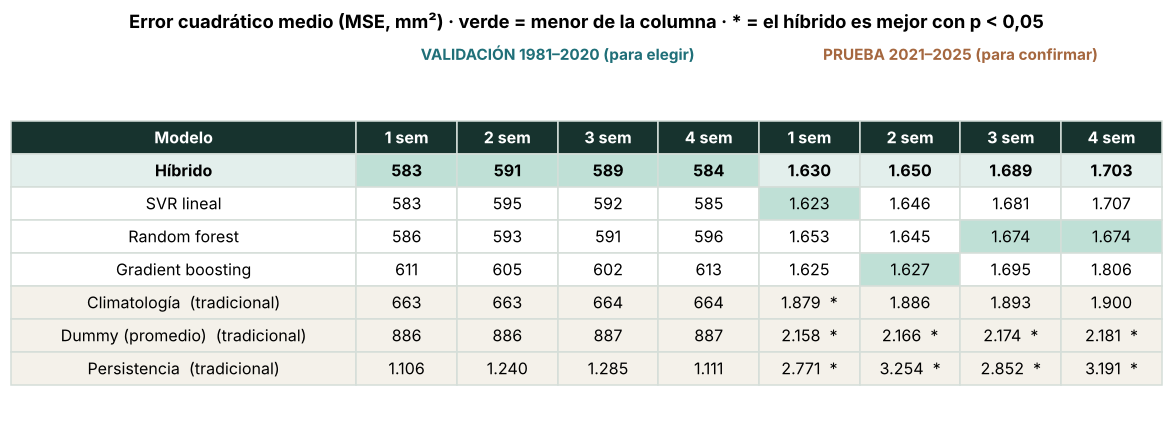

In [14]:
# Cuadro resumen: MSE en validación (para elegir) y en prueba (para confirmar)
orden = MODELOS[::-1][:1] + ["SVR lineal", "Random forest", "Gradient boosting"] + REFERENCIAS
celdas, colores = [], []
for m in orden:
    base = "#F4F1EA" if m in REFERENCIAS else ("#E3EFEC" if m == "Híbrido" else "white")
    fila, col = [m + ("  (tradicional)" if m in REFERENCIAS else "")], [base]
    for h in HORIZONTES:
        v = tabla_val.loc[m, h]; fila.append(f"{v:,.0f}".replace(",", ".")); col.append("#BFE0D6" if v == tabla_val[h].min() else base)
    for h in HORIZONTES:
        v = tabla_pru.loc[m, h]; p = PRU[(PRU.h == h) & (PRU.modelo == m)].p_valor.iloc[0]
        fila.append(f"{v:,.0f}".replace(",", ".") + ("  *" if m != "Híbrido" and p < 0.05 else "")); col.append("#BFE0D6" if v == tabla_pru[h].min() else base)
    celdas.append(fila); colores.append(col)
fig, ax = plt.subplots(figsize=(13.5, 4.3)); ax.axis("off")
tb = ax.table(cellText=celdas, colLabels=["Modelo"] + [f"{h} sem" for h in HORIZONTES] * 2, cellColours=colores, cellLoc="center",
              loc="center", colWidths=[0.3] + [0.0875] * 8)
tb.auto_set_font_size(False); tb.set_fontsize(10.5); tb.scale(1, 1.8)
for (r, c), cell in tb.get_celld().items():
    cell.set_edgecolor("#D5DED9")
    if r == 0: cell.set_facecolor("#17332E"); cell.set_text_props(color="white", weight="bold")
    if r > 0 and celdas[r - 1][0] == "Híbrido": cell.set_text_props(weight="bold")
ax.text(0.475, 1.03, "VALIDACIÓN 1981–2020 (para elegir)", transform=ax.transAxes, ha="center", weight="bold", color="#1F6F78")
ax.text(0.825, 1.03, "PRUEBA 2021–2025 (para confirmar)", transform=ax.transAxes, ha="center", weight="bold", color="#A5673F")
ax.set_title("Error cuadrático medio (MSE, mm²) · verde = menor de la columna · * = el híbrido es mejor con p < 0,05", pad=28, weight="bold")
plt.show()

**Interpretación.** La prueba confirma la elección, con dos lecturas distintas:

- **Frente a los métodos tradicionales, el híbrido es claramente superior.** Reduce el RMSE entre 11,6 % y 13,1 % frente al promedio (Dummy) y entre 23,0 % y 28,8 % frente a la persistencia, con diferencias significativas en los cuatro horizontes (Diebold-Mariano, p ≤ 0,025). Frente a la climatología la mejora es de 5,3 % a 6,9 %, significativa a 1 semana (p = 0,041); a 2, 3 y 4 semanas el IC 95 % incluye el cero.
- **Frente a los otros modelos de ML, la prueba no puede separarlos.** Las diferencias con el SVR, el random forest y el gradient boosting son de décimas de punto y ninguna es significativa (p entre 0,10 y 0,95). En 260 semanas de un periodo atípico (2021 muy seco, 2022–2025 muy lluviosos), cada horizonte lo "gana" un modelo distinto: es ruido. Por eso la elección se hace con la validación, de unas 1.390 semanas, y la prueba solo confirma que el elegido no falla con datos nuevos. El híbrido nunca queda último entre los modelos de ML, ni en validación ni en prueba.

## 5.4 Curvas ROC: ¿qué tan bien ordena las semanas?

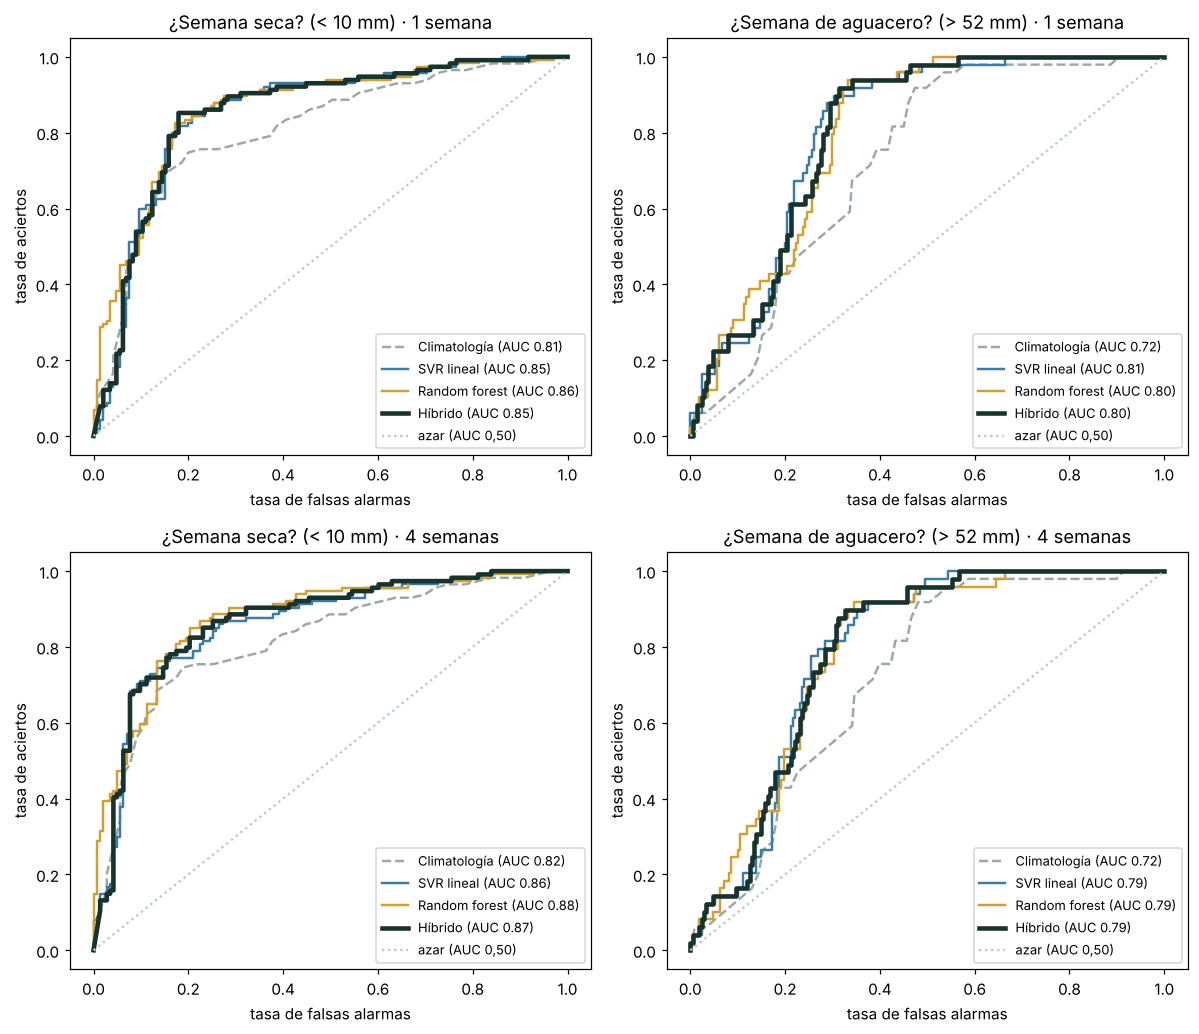

In [17]:
fig, axs = plt.subplots(2, 2, figsize=(11, 9.5))
for fila, h in enumerate([1, 4]):
    P = R[h]["P"]; u = R[h]["umbral"]
    for col, (obj, sg, tit) in enumerate([(P.y < 10, -1, "¿Semana seca? (< 10 mm)"), (P.y > u, 1, f"¿Semana de aguacero? (> {u:.0f} mm)")]):
        ax = axs[fila, col]
        for m in ["Climatología", "SVR lineal", "Random forest", "Híbrido"]:
            f, v, _ = roc_curve(obj, sg * P[m])
            ax.plot(f, v, color=COLOR[m], lw=3 if m == "Híbrido" else 1.6, ls="--" if m == "Climatología" else "-",
                    label=f"{m} (AUC {roc_auc_score(obj, sg * P[m]):.2f})")
        ax.plot([0, 1], [0, 1], ":", color="#B9C9C1", label="azar (AUC 0,50)")
        ax.set_title(f"{tit} · {h} semana{'s' if h > 1 else ''}"); ax.set_xlabel("tasa de falsas alarmas"); ax.set_ylabel("tasa de aciertos")
        ax.legend(fontsize=8.5, loc="lower right")
plt.tight_layout(); plt.show()

In [18]:
# AUC en prueba con IC 95 % (bootstrap por bloques)
filas = []
for h in HORIZONTES:
    P = R[h]["P"]; y = P.y.values; u = R[h]["umbral"]; bl = max(8, h + 4)
    for m in ["Climatología", "SVR lineal", "Random forest", "Gradient boosting", "Híbrido"]:
        p = P[m].values; fila = {"h": h, "modelo": m}
        for nombre, obj, sg in [("seca", y < 10, -1), ("aguacero", y > u, 1)]:
            ic = hb.bootstrap_bloques(lambda i: roc_auc_score(obj[i], sg * p[i]) if 0 < obj[i].sum() < len(i) else np.nan, len(y), bl, n_boot=1000)
            fila[f"AUC {nombre}"] = f"{roc_auc_score(obj, sg * p):.3f} [{ic[0]:.3f}, {ic[1]:.3f}]"
        filas.append(fila)
AUC = pd.DataFrame(filas)
AUC[AUC.h.isin([1, 4])].set_index(["h", "modelo"])

AUC seca          AUC aguacero
h modelo                                                       
1 Climatología       0.810 [0.734, 0.887]  0.723 [0.615, 0.807]
  SVR lineal         0.851 [0.801, 0.909]  0.807 [0.713, 0.875]
  Random forest      0.862 [0.806, 0.912]  0.801 [0.707, 0.869]
  Gradient boosting  0.856 [0.804, 0.914]  0.801 [0.707, 0.873]
  Híbrido            0.853 [0.802, 0.911]  0.805 [0.711, 0.873]
4 Climatología       0.818 [0.739, 0.895]  0.719 [0.606, 0.803]
  SVR lineal         0.859 [0.815, 0.911]  0.789 [0.693, 0.857]
  Random forest      0.877 [0.830, 0.923]  0.788 [0.696, 0.853]
  Gradient boosting  0.860 [0.808, 0.906]  0.767 [0.667, 0.836]
  Híbrido            0.867 [0.827, 0.918]  0.790 [0.693, 0.857]

**Interpretación.** Las curvas de los modelos de ML están por encima de la climatología en casi todo el rango, sobre todo en los aguaceros: a 1 semana el AUC para aguacero sube de 0,723 (climatología) a 0,801–0,807, y para semana seca, de 0,810 a 0,851–0,862. Entre los modelos de ML las curvas casi se superponen. Los IC 95 % de los AUC se traslapan con los de la climatología (por ejemplo, 0,805 [0,711; 0,873] frente a 0,723 [0,615; 0,807] en aguaceros a 1 semana): la mejora en AUC es consistente en los cuatro horizontes, pero con 5 años de prueba no alcanza a ser estadísticamente segura.

## 5.5 Semanas de aguacero, año a año

In [21]:
filas = []
for h in HORIZONTES:
    P = R[h]["P"]; y = P.y.values; u = R[h]["umbral"]; bl = max(8, h + 4)
    for m in ["SVR lineal", "Random forest", "Gradient boosting", "Híbrido"]:
        filas.append({"h": h, "modelo": m, **hb.tabla_aguaceros(y, P[m], u)})
    ext = y > u
    pod = lambda p, i: ((p[i] > u) & ext[i]).sum() / max(ext[i].sum(), 1)
    csi = lambda p, i: ((p[i] > u) & ext[i]).sum() / max(((p[i] > u) | ext[i]).sum(), 1)
    for ref in ["SVR lineal", "Random forest"]:
        a, b = P["Híbrido"].values, P[ref].values
        filas[-1][f"ΔPOD vs {ref}"] = "[{:+.2f}, {:+.2f}]".format(*hb.bootstrap_bloques(lambda i: pod(a, i) - pod(b, i), len(y), bl))
        filas[-1][f"ΔCSI vs {ref}"] = "[{:+.2f}, {:+.2f}]".format(*hb.bootstrap_bloques(lambda i: csi(a, i) - csi(b, i), len(y), bl))
AG = pd.DataFrame(filas)
AG.round(3).fillna("")

,h,modelo,aguaceros,detectados,falsas_alarmas,POD,FAR,CSI,ΔPOD vs SVR lineal,ΔCSI vs SVR lineal,ΔPOD vs Random forest,ΔCSI vs Random forest
0,1,SVR lineal,49,12,23,0.245,0.657,0.167,,,,
1,1,Random forest,49,15,23,0.306,0.605,0.208,,,,
2,1,Gradient boosting,49,26,45,0.531,0.634,0.277,,,,
3,1,Híbrido,49,20,37,0.408,0.649,0.233,"[+0.04, +0.29]","[-0.01, +0.16]","[+0.00, +0.19]","[-0.05, +0.09]"
4,2,SVR lineal,49,13,24,0.265,0.649,0.178,,,,
5,2,Random forest,49,19,30,0.388,0.612,0.241,,,,
6,2,Gradient boosting,49,24,38,0.490,0.613,0.276,,,,
7,2,Híbrido,49,22,37,0.449,0.627,0.256,"[+0.09, +0.27]","[+0.02, +0.13]","[+0.00, +0.14]","[-0.02, +0.07]"
8,3,SVR lineal,49,13,24,0.265,0.649,0.178,,,,
9,3,Random forest,49,24,39,0.490,0.619,0.273,,,,


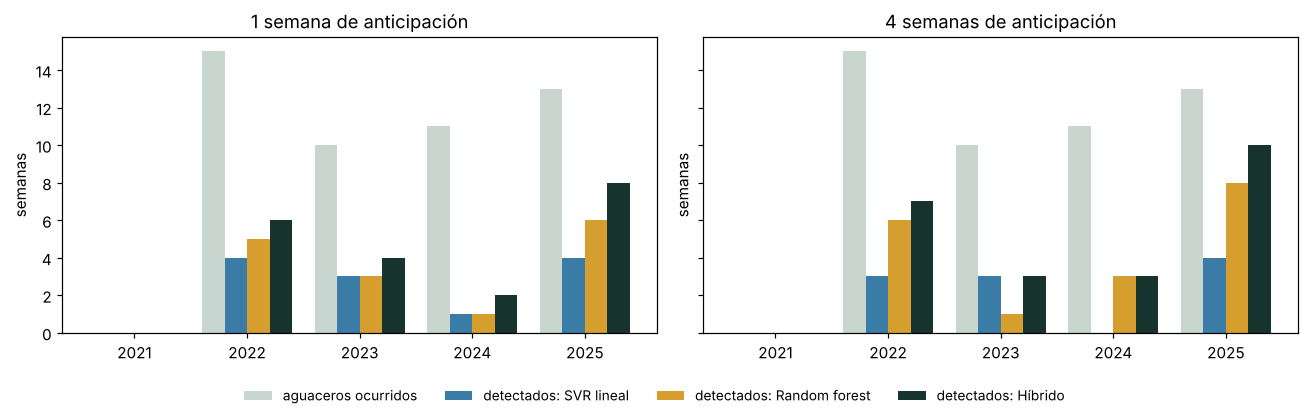

aguaceros     SVR lineal    Random forest    Híbrido    
h            1   4          1  4             1  4       1   4
año                                                          
2021         0   0          0  0             0  0       0   0
2022        15  15          4  3             5  6       6   7
2023        10  10          3  3             3  1       4   3
2024        11  11          1  0             1  3       2   3
2025        13  13          4  4             6  8       8  10

In [22]:
# Año a año: aguaceros observados y detectados con 1 y 4 semanas de anticipación
filas = []
for h in [1, 4]:
    P = R[h]["P"].assign(anio=lambda d: d.fecha.dt.year); u = R[h]["umbral"]
    for anio, g in P.groupby("anio"):
        ext = g.y > u
        filas.append({"h": h, "año": anio, "aguaceros": int(ext.sum()),
                      **{m: int(((g[m] > u) & ext).sum()) for m in ["SVR lineal", "Random forest", "Híbrido"]}})
ANIO = pd.DataFrame(filas)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, h in zip(axs, [1, 4]):
    d = ANIO[ANIO.h == h].set_index("año"); x = np.arange(len(d))
    ax.bar(x - 0.3, d.aguaceros, 0.2, color="#C9D6D0", label="aguaceros ocurridos")
    for k, m in enumerate(["SVR lineal", "Random forest", "Híbrido"]):
        ax.bar(x - 0.1 + 0.2 * k, d[m], 0.2, color=COLOR[m], label=f"detectados: {m}")
    ax.set_xticks(x); ax.set_xticklabels(d.index); ax.set_title(f"{h} semana{'s' if h > 1 else ''} de anticipación"); ax.set_ylabel("semanas")
h_, l_ = axs[0].get_legend_handles_labels(); fig.legend(h_, l_, loc="lower center", ncol=4, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()
ANIO.pivot(index="año", columns="h", values=["aguaceros", "SVR lineal", "Random forest", "Híbrido"])

**Interpretación.** En la prueba hubo 49 semanas de aguacero, ninguna en 2021. El híbrido detecta entre 20 y 25 de ellas según el horizonte (POD de 0,41 a 0,51), frente a 10 a 13 del SVR (POD de 0,20 a 0,27). **La mejora sobre el SVR es significativa en los cuatro horizontes**: el IC 95 % de la diferencia de POD va de [+0,04; +0,29] a 1 semana hasta [+0,11; +0,41] a 4 semanas. Además, el CSI, que también castiga las falsas alarmas, mejora con significancia a 2, 3 y 4 semanas. Frente al random forest la detección también es mayor; a 1, 2 y 4 semanas el IC de la diferencia de POD no baja de cero, pero el CSI no es significativamente distinto.

La tabla año a año muestra que la ventaja no viene de un solo año: con 4 semanas de anticipación, el híbrido detecta 7 de 15 aguaceros en 2022 (el SVR, 3), 3 de 11 en 2024 (el SVR, 0) y 10 de 13 en 2025 (el SVR, 4). El gradient boosting detecta aún más en la prueba (POD de 0,49 a 0,53), pero a cambio de más falsas alarmas y de un mayor error en validación; en validación su CSI es menor que el del híbrido (0,215 frente a 0,248).

**Límite que hay que reconocer:** cerca de dos de cada tres alertas de aguacero del híbrido no se cumplen (FAR de 0,63 a 0,65), igual que en los demás modelos.

## 5.6 ¿Con qué porcentaje de acierto?

"Acierto" puede significar tres cosas distintas, y conviene separarlas:

1. **El intervalo:** ¿con qué frecuencia la lluvia real cae dentro del rango del 95 % que da el híbrido?
2. **El error en milímetros:** ¿cuántas semanas se equivoca por menos de 10 o 20 mm?
3. **Seca o con lluvia:** ¿acierta si la semana tendrá menos de 10 mm? Para esta pregunta se compara con un **clasificador logístico**, que está hecho para responder sí o no (la regresión logística del dashboard), entrenado con el mismo protocolo.

In [25]:
filas = []
for h in HORIZONTES:
    P = R[h]["P"]; y = P.y.values; bl = max(8, h + 4)
    den = (y >= P.inf95.values) & (y <= P.sup95.values)
    e = np.abs(y - P["Híbrido"].values)
    ic = hb.bootstrap_bloques(lambda i: den[i].mean(), len(y), bl)
    filas.append({"h": h, "intervalo 95 % contiene la lluvia real": f"{den.mean():.1%} [{ic[0]:.1%}, {ic[1]:.1%}]",
                  "ancho medio del intervalo (mm)": round(float((P.sup95 - P.inf95).mean()), 1),
                  "error mediano (mm)": round(float(np.median(e)), 1), "semanas con error ≤ 10 mm": f"{np.mean(e <= 10):.0%}",
                  "semanas con error ≤ 20 mm": f"{np.mean(e <= 20):.0%}",
                  "error mediano en semanas secas (mm)": round(float(np.median(e[y < 10])), 1),
                  "error mediano en aguaceros (mm)": round(float(np.median(e[y > R[h]['umbral']])), 1)})
pd.DataFrame(filas).set_index("h").T

h,1,2,3,4
intervalo 95 % contiene la lluvia real,"91.9% [87.3%, 95.8%]","87.6% [80.7%, 93.1%]","85.7% [78.3%, 91.9%]","84.4% [76.7%, 90.7%]"
ancho medio del intervalo (mm),99.7,100.5,102.5,95.9
error mediano (mm),15.4,16.3,15.7,15.8
semanas con error ≤ 10 mm,35%,34%,33%,38%
semanas con error ≤ 20 mm,60%,59%,57%,58%
error mediano en semanas secas (mm),9.7,8.8,9.1,8.7
error mediano en aguaceros (mm),35.8,31.6,32.1,34.9


In [26]:
# ¿Semana seca? Modelos de milímetros (pronóstico < 10 mm) frente a un clasificador logístico (probabilidad ≥ 0,5)
def logistica(C):
    return Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler()),
                     ("lg", LogisticRegression(C=C, class_weight="balanced", max_iter=5000))])
filas = []
for h in HORIZONTES:
    r = R[h]; tr, te, cols, sp = r["tr"], r["te"], r["cols"], r["sp"]
    ys_tr, y = (tr.y < 10).astype(int), (te.y < 10).values
    aucs = {C: np.mean([roc_auc_score(ys_tr[b], logistica(C).fit(tr.loc[a, cols], ys_tr[a]).predict_proba(tr.loc[b, cols])[:, 1]) for a, b in sp])
            for C in (0.001, 0.01, 0.1, 1.0)}
    Cmej = max(aucs, key=aucs.get)
    p_lg = logistica(Cmej).fit(tr[cols], ys_tr).predict_proba(te[cols])[:, 1]
    bl = max(8, h + 4); P = r["P"]
    opciones = {"Climatología (< 10 mm)": P["Climatología"].values < 10, "Híbrido (< 10 mm)": P["Híbrido"].values < 10,
                "Random forest (< 10 mm)": P["Random forest"].values < 10, "Logística (p ≥ 0,5)": p_lg >= 0.5}
    for n, pr in opciones.items():
        ic = hb.bootstrap_bloques(lambda i: np.mean(pr[i] == y[i]), len(y), bl)
        filas.append({"h": h, "método": n, "acierto": f"{np.mean(pr == y):.1%} [{ic[0]:.1%}, {ic[1]:.1%}]"})
    filas.append({"h": h, "método": "Logística: AUC", "acierto": f"{roc_auc_score(y, p_lg):.3f} (C = {Cmej})"})
    filas.append({"h": h, "método": "Trivial: siempre 'con lluvia'", "acierto": f"{np.mean(~y):.1%}"})
SECA = pd.DataFrame(filas)
SECA.pivot(index="método", columns="h", values="acierto")

h,1,2,3,4
método,,,,
Climatología (< 10 mm),"76.5% [68.8%, 85.0%]","76.8% [68.7%, 84.9%]","77.1% [69.0%, 84.9%]","77.0% [69.3%, 84.8%]"
Híbrido (< 10 mm),"70.4% [61.5%, 80.0%]","71.8% [64.1%, 81.5%]","71.3% [62.8%, 80.2%]","72.0% [63.8%, 80.5%]"
"Logística (p ≥ 0,5)","78.8% [73.1%, 85.8%]","79.9% [74.5%, 86.5%]","80.2% [74.0%, 86.4%]","79.8% [74.3%, 86.0%]"
Logística: AUC,0.856 (C = 0.1),0.865 (C = 0.1),0.871 (C = 0.1),0.867 (C = 0.1)
Random forest (< 10 mm),"73.1% [64.6%, 81.9%]","73.4% [65.3%, 82.2%]","73.3% [64.7%, 81.8%]","76.7% [68.9%, 84.4%]"
Trivial: siempre 'con lluvia',55.8%,55.6%,55.4%,55.6%


**Interpretación.**

- **El intervalo del 95 %** contiene la lluvia real en el 91,9 % de las semanas a 1 semana (IC 87,3 % a 95,8 %) y en el 84,4 % a 4 semanas (IC 76,7 % a 90,7 %). A 1 semana la cobertura nominal del 95 % está dentro del IC; a horizontes mayores el intervalo es algo corto, por el cambio de régimen del periodo de prueba.
- **El error típico** del híbrido es de unos 15–16 mm (mediana). En semanas secas el error mediano es de 9–10 mm; en aguaceros, de 32–36 mm.
- **Para la pregunta "¿será seca?"**, los modelos de milímetros no son la herramienta adecuada: con la regla "pronóstico < 10 mm" aciertan el 70–77 %, igual o menos que la climatología (76,5–77,1 %), porque apuntan a la media y la media de una semana seca suele quedar por encima de 10 mm. El **clasificador logístico** acierta el 78,8–80,2 % de las semanas (IC 95 % de 73,1 % a 86,5 %), con AUC de 0,856 a 0,871. La mejora sobre la climatología es consistente, pero sus IC se traslapan.

**En resumen, para la finca:** el híbrido responde *cuánto* lloverá (con su intervalo) y detecta las semanas de aguacero; la logística responde *si* la semana será seca.

## 5.7 ¿Por qué funciona la combinación?

In [29]:
filas = []
for h in HORIZONTES:
    V = R[h]["oof"]; V = V[V.fold >= 1]; j = R[h]["juez"]
    e_svr, e_rf = V.y - V["SVR lineal"], V.y - V["Random forest"]
    ext = V.y > V.umbral
    filas.append({"h": h, "correlación de errores SVR–RF": e_svr.corr(e_rf), "suma de pesos w1 + w2": j["w_svr"] + j["w_rf"],
                  "lluvia media en aguaceros (mm)": V.y[ext].mean(), "pronóstico medio SVR en aguaceros": V["SVR lineal"][ext].mean(),
                  "pronóstico medio RF en aguaceros": V["Random forest"][ext].mean(), "pronóstico medio híbrido en aguaceros": V["Híbrido"][ext].mean()})
pd.DataFrame(filas).set_index("h").round(3)

,correlación de errores SVR–RF,suma de pesos w1 + w2,lluvia media en aguaceros (mm),pronóstico medio SVR en aguaceros,pronóstico medio RF en aguaceros,pronóstico medio híbrido en aguaceros
h,,,,,,
1,0.982,1.136,73.319,32.206,33.445,36.738
2,0.981,1.186,73.421,31.884,31.861,37.836
3,0.977,1.190,73.421,31.694,32.703,38.360
4,0.974,1.196,73.421,31.960,32.334,38.160


**Interpretación.** Los errores del SVR y del random forest están muy correlacionados (0,97 a 0,98): se equivocan casi en las mismas semanas. Por eso la ventaja del híbrido **no** viene de que un modelo compense al otro. Viene del juez: los dos modelos se quedan cortos en las semanas lluviosas, porque al minimizar el error cuadrático y estar regularizados tiran hacia el promedio. En los aguaceros de validación llovieron en promedio 73 mm y ambos pronosticaron unos 32 mm. Con pesos que suman 1,14 a 1,20, el juez corrige parte de ese encogimiento y el híbrido pronostica 37–38 mm en esas semanas. Esta corrección se aprendió solo con los simulacros, y por eso mejora la detección de aguaceros sin aumentar el error cuadrático medio.

## 5.8 ¿Y XGBoost? El gradient boosting queda descartado

In [32]:
gb = pd.DataFrame({"MSE validación (puesto entre 4)": [f"{tabla_val.loc['Gradient boosting', h]:.0f} ({int(tabla_val[h].loc[MODELOS].rank().loc['Gradient boosting'])}.º)" for h in HORIZONTES],
                   "MSE validación del híbrido": [round(tabla_val.loc["Híbrido", h]) for h in HORIZONTES],
                   "MSE prueba": [round(tabla_pru.loc["Gradient boosting", h]) for h in HORIZONTES],
                   "MSE prueba del híbrido": [round(tabla_pru.loc["Híbrido", h]) for h in HORIZONTES],
                   "Diebold-Mariano p (vs híbrido)": [round(PRU[(PRU.h == h) & (PRU.modelo == "Gradient boosting")].p_valor.iloc[0], 3) for h in HORIZONTES],
                   "hiperparámetros elegidos": [str(R[h]["par_gb"]) for h in HORIZONTES]}, index=pd.Index(HORIZONTES, name="h"))
gb

,MSE validación (puesto entre 4),MSE validación del híbrido,MSE prueba,MSE prueba del híbrido,Diebold-Mariano p (vs híbrido),hiperparámetros elegidos
h,,,,,,
1,611 (4.º),583,1625,1630,0.838,"{'loss': 'squared_error', 'learning_rate': 0.0..."
2,605 (4.º),591,1627,1650,0.764,"{'loss': 'poisson', 'learning_rate': 0.03, 'ma..."
3,602 (4.º),589,1695,1689,0.944,"{'loss': 'poisson', 'learning_rate': 0.03, 'ma..."
4,613 (4.º),584,1806,1703,0.101,"{'loss': 'squared_error', 'learning_rate': 0.0..."


**Interpretación.** El gradient boosting (equivalente a XGBoost) queda descartado por el criterio fijado de antemano: en validación es el último de los cuatro modelos de ML en los cuatro horizontes, con un MSE de 602 a 613 mm² frente a 583 a 591 del híbrido. En la prueba gana por poco a 1 y 2 semanas, sin significancia (p = 0,84 y 0,76), y a 4 semanas tiene el mayor error de los modelos de ML (1.806 frente a 1.703 del híbrido, p = 0,101). Es decir, es inestable: lo que gana en un horizonte lo pierde en otro.

## 5.9 Pronóstico para la planificación

Con el modelo elegido se genera `data/processed/pronostico_lluvia_semanal.csv`, que usa el capítulo 6. Para las semanas 1 a 4 se usa el híbrido, reentrenado con todos los datos, con su intervalo conformal; desde la semana 5, los cuantiles climatológicos. También se guardan los resultados que muestra el dashboard.

In [35]:
g_obj = df[df.punto == cfg.PUNTO_OBJETIVO]; ultima = g_obj.fecha.max()
filas = []
for h in HORIZONTES:
    r = R[h]; tabla_h = md.tabla_modelado(df, h); cols = r["cols"]
    tr_h = tabla_h[tabla_h.fecha + pd.Timedelta(days=7 * h) <= ultima]
    s = md.pipeline_svr(C=r["par_svr"]["C"], log_objetivo=bool(r["par_svr"]["log1p"]), loss=r["par_svr"]["loss"]).fit(tr_h[cols], tr_h.y)
    f = hb.pipeline_rf(**r["par_rf"]).fit(tr_h[cols], tr_h.y)
    X_e = md.construir_predictoras(g_obj.set_index("fecha")).join(md.componentes_ciclicos([ultima], h), how="right")
    for c in ["lat", "lon", "elevacion_m"]:
        X_e[c] = g_obj[c].iloc[0]
    p = float(hb.aplicar_juez(r["juez"], s.predict(X_e[cols]), f.predict(X_e[cols]))[0])
    filas.append({"semana": h, "fuente": "modelo", **{f"P_q{int(q * 1000):03d}": max(0.0, p + c) for q, c in r["cal"].items()}})
sem = g_obj.set_index("fecha")["PRECTOTCORR"].resample("W").sum()
sem_df = pd.DataFrame({"y": sem.values, "woy": sem.index.isocalendar().week.clip(upper=52).values})
for h in range(5, 53):
    woy = min(52, int((ultima + pd.Timedelta(days=7 * h - 3)).isocalendar().week))
    v = sem_df[sem_df.woy == woy]["y"]
    filas.append({"semana": h, "fuente": "climatología", **{f"P_q{int(q * 1000):03d}": float(v.quantile(q)) for q in (0.025, 0.05, 0.5, 0.95, 0.975)}})
pronostico = pd.DataFrame(filas)
pronostico.to_csv(cfg.DATA_PROCESSED / "pronostico_lluvia_semanal.csv", index=False)

# Resultados para el dashboard
pd.concat([R[h]["P"].assign(h=h, umbral=R[h]["umbral"]) for h in HORIZONTES]).to_csv(cfg.DATA_PROCESSED / "hibrido_prueba.csv", index=False)
VAL.assign(etapa="validación").to_csv(cfg.DATA_PROCESSED / "hibrido_metricas_validacion.csv", index=False)
PRU.assign(etapa="prueba").to_csv(cfg.DATA_PROCESSED / "hibrido_metricas_prueba.csv", index=False)
AG.to_csv(cfg.DATA_PROCESSED / "hibrido_aguaceros.csv", index=False)
ANIO.to_csv(cfg.DATA_PROCESSED / "hibrido_aguaceros_anio.csv", index=False)
SECA.to_csv(cfg.DATA_PROCESSED / "hibrido_semana_seca.csv", index=False)
pd.DataFrame([{"h": h, **R[h]["juez"], **{f"cal_{q}": c for q, c in R[h]["cal"].items()}} for h in HORIZONTES]).to_csv(cfg.DATA_PROCESSED / "hibrido_pesos.csv", index=False)
print(f"Pronóstico desde {ultima.date()} con el híbrido: semanas 1 a 4 con el modelo y 5 a 52 con climatología")
pronostico.head(6).round(2)

Pronóstico desde 2025-12-31 con el híbrido: semanas 1 a 4 con el modelo y 5 a 52 con climatología


,semana,fuente,P_q025,P_q050,P_q500,P_q950,P_q975
0,1,modelo,0.0,0.0,0.00,50.80,75.67
1,2,modelo,0.0,0.0,0.00,50.69,77.26
2,3,modelo,0.0,0.0,0.00,51.06,79.12
3,4,modelo,0.0,0.0,0.00,49.33,74.00
4,5,climatología,0.0,0.0,0.01,5.77,11.26
5,6,climatología,0.0,0.0,0.07,4.04,10.80


**Interpretación.** Para la siembra a comienzos de enero, el híbrido pronostica una mediana de 0 mm en las semanas 1 a 4, con un percentil 95 de unos 50 mm: es plena temporada seca, igual que con los modelos de los capítulos 3 y 4. El capítulo 6 usa este pronóstico para calcular las hectáreas disponibles.